In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import yfinance as yf

# Clean Pair-Divergence Market Data

Validate downloaded market data, remove known data-quality problems, and construct the feature-ready market dataset.

## Load Market Data

In [2]:
# Locate repository root
currentDirectory = Path.cwd()

possibleRoots = [
    currentDirectory,
    currentDirectory.parent,
    currentDirectory.parent.parent
]

repositoryRoot = None

for directory in possibleRoots:
    rawDataPath = directory/"data"/"pairDivergence"/"pairDivergenceData_Raw.parquet"

    if rawDataPath.exists():
        repositoryRoot = directory
        break

if repositoryRoot is None:
    raise FileNotFoundError("Could not find pairDivergenceData_Raw.parquet")

# Define market data paths
rawDataPath = repositoryRoot/"data"/"pairDivergence"/"pairDivergenceData_Raw.parquet"
outputPath = repositoryRoot/"data"/"pairDivergence"/"pairDivergenceData.parquet"

# Load raw Yahoo market data
marketData = pd.read_parquet(rawDataPath)

print(f"Rows: {len(marketData):,}")
print(f"Symbols: {marketData['symbol'].nunique():,}")
print(f"First date: {marketData['date'].min().date()}")
print(f"Last date: {marketData['date'].max().date()}")

Rows: 8,835,632
Symbols: 5,234
First date: 2018-01-02
Last date: 2026-06-30


In [3]:
# Validate dataset structure
expectedColumns = ["date", "symbol", "open", "high", "low", "close", "adjClose", "volume"]

if marketData.columns.tolist() != expectedColumns:
    raise ValueError(f"Unexpected columns: {marketData.columns.tolist()}")

duplicateCount = marketData.duplicated(subset=["date", "symbol"]).sum()
missingValueCounts = marketData[["open", "high", "low", "close", "adjClose", "volume"]].isna().sum()

missingValueSymbols = sorted(
    marketData.loc[
        marketData[["open", "high", "low", "close", "adjClose", "volume"]].isna().any(axis=1),
        "symbol"
    ].unique()
)

print(f"Duplicate date-symbol rows: {duplicateCount:,}")
print()
print("Missing values:")
print(missingValueCounts.to_string())
print()
print(f"Symbols with missing values: {len(missingValueSymbols):,}")
print(missingValueSymbols)

Duplicate date-symbol rows: 0

Missing values:
open          0
high          0
low           0
close         0
adjClose    732
volume        0

Symbols with missing values: 1
['DEC']


### Correct Listing History

Yahoo includes `DEC` observations before Diversified Energy began trading on the NYSE. Since this project uses a U.S. equity universe, observations before the NYSE listing date are excluded.

In [4]:
# Remove DEC history preceding its NYSE listing
marketData = marketData.loc[
    ~((marketData["symbol"] == "DEC") & (marketData["date"] < "2023-12-18"))
].copy().reset_index(drop=True)

print(f"DEC first retained date: {marketData.loc[marketData['symbol'] == 'DEC', 'date'].min().date()}")
print(f"Missing adjClose values: {marketData['adjClose'].isna().sum():,}")

DEC first retained date: 2023-12-18
Missing adjClose values: 0


## Validate OHLCV Observations

In [5]:
# Identify objectively invalid OHLCV observations
nonpositivePriceMask = (marketData[["open", "high", "low", "close", "adjClose"]] <= 0).any(axis=1)

invalidHighMask = (
    (marketData["high"] < marketData["open"]) |
    (marketData["high"] < marketData["low"]) |
    (marketData["high"] < marketData["close"])
)

invalidLowMask = (
    (marketData["low"] > marketData["open"]) |
    (marketData["low"] > marketData["high"]) |
    (marketData["low"] > marketData["close"])
)

negativeVolumeMask = marketData["volume"] < 0

priceAnomalyMask = (
    nonpositivePriceMask |
    invalidHighMask |
    invalidLowMask |
    negativeVolumeMask
)

priceAnomalies = marketData.loc[
    priceAnomalyMask,
    ["date", "symbol", "open", "high", "low", "close", "adjClose", "volume"]
]

print(f"Nonpositive price rows: {nonpositivePriceMask.sum():,}")
print(f"Invalid high rows: {invalidHighMask.sum():,}")
print(f"Invalid low rows: {invalidLowMask.sum():,}")
print(f"Negative volume rows: {negativeVolumeMask.sum():,}")
print(f"Unique anomalous rows: {len(priceAnomalies):,}")

display(priceAnomalies)

Nonpositive price rows: 2
Invalid high rows: 1
Invalid low rows: 6
Negative volume rows: 0
Unique anomalous rows: 9


,date,symbol,open,high,low,close,adjClose,volume
1673885,2021-05-05,CIG-C,1.532544,1.609467,1.538461,1.609467,1.051378,22722.0
1827514,2021-10-08,CNL,1.205000,2.410000,0.000000,1.205000,1.205000,500.0
3839587,2021-05-05,HUBB,195.979996,198.639999,196.210007,198.130005,181.720032,127234.0
7086103,2021-05-05,SHEL,39.060001,39.839901,39.445000,39.779999,32.394276,3225346.0
7086536,2023-01-24,SHEL,51.259998,58.400002,56.259998,57.990002,50.033306,3125185.0
7142819,2021-05-05,SITC,17.696529,17.529917,17.125290,17.137190,4.175779,818516.0
7356452,2021-09-29,SPRC,24570.000000,26535.599609,0.000000,26535.599609,26535.599609,1.0
8029147,2021-05-05,UA,20.870001,21.825001,21.000000,21.129999,21.129999,5213105.0
8547166,2021-05-05,WLY,59.810001,61.299999,59.950001,61.200001,51.322136,261515.0


In [6]:
# Remove objectively invalid OHLCV observations
rowsBeforeCleaning = len(marketData)

marketData = marketData.loc[~priceAnomalyMask].copy().reset_index(drop=True)

rowsRemoved = rowsBeforeCleaning - len(marketData)

print(f"Invalid rows removed: {rowsRemoved:,}")
print(f"Remaining rows: {len(marketData):,}")

Invalid rows removed: 9
Remaining rows: 8,834,879


## Check Adjusted Returns

In [7]:
# Calculate one-day adjusted-close log returns
returnDiagnostics = marketData[["date", "symbol", "adjClose"]].copy()
returnDiagnostics = returnDiagnostics.sort_values(["symbol", "date"]).reset_index(drop=True)

previousAdjClose = returnDiagnostics.groupby("symbol")["adjClose"].shift(1)

returnDiagnostics["adjReturn1"] = np.log(returnDiagnostics["adjClose"] / previousAdjClose)

# Identify unusually large returns for diagnostic review
extremeAdjustedReturns = returnDiagnostics.loc[returnDiagnostics["adjReturn1"].abs() > 0.5].copy()

print(f"Extreme adjusted returns: {len(extremeAdjustedReturns):,}")
print(f"Symbols affected: {extremeAdjustedReturns['symbol'].nunique():,}")

Extreme adjusted returns: 6,725
Symbols affected: 1,782


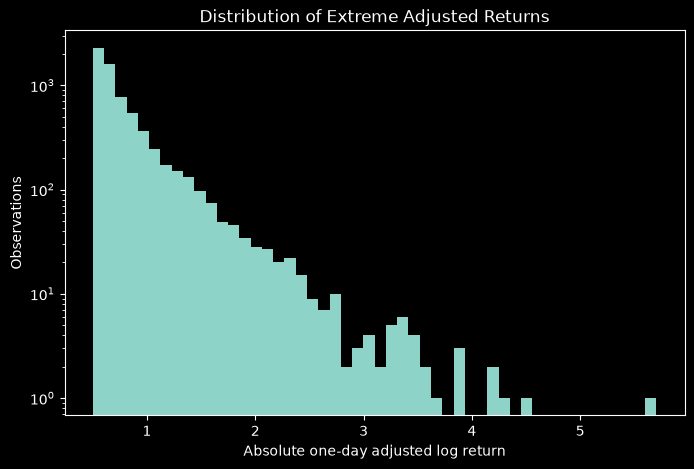

In [8]:
# Visualize the magnitude of extreme adjusted returns
absoluteExtremeReturns = extremeAdjustedReturns["adjReturn1"].abs()

plt.figure(figsize=(8, 5))
plt.hist(absoluteExtremeReturns, bins=50)

plt.yscale("log")
plt.xlabel("Absolute one-day adjusted log return")
plt.ylabel("Observations")
plt.title("Distribution of Extreme Adjusted Returns")

plt.show()

Extreme adjusted returns exhibit a continuous distribution. Because unusually large movements are common among small and thinly traded securities, observations are not removed based on return magnitude or reversal patterns.

Yahoo Finance adjusted-close values are retained as provided. The dataset may therefore contain residual vendor-specific historical or corporate-action errors, which are acknowledged as a limitation of the research data source.

## Audit Symbol Histories

In [9]:
# Summarize available history for each symbol
symbolHistories = marketData.groupby("symbol").agg(
    firstDate=("date", "min"),
    lastDate=("date", "max"),
    observations=("date", "size")
).reset_index()

print(f"Symbols with market data: {len(symbolHistories):,}")
print(f"Minimum observations: {symbolHistories['observations'].min():,}")
print(f"Median observations: {symbolHistories['observations'].median():,.0f}")
print(f"Maximum observations: {symbolHistories['observations'].max():,}")

display(symbolHistories.sort_values("observations").head(20))

Symbols with market data: 5,234
Minimum observations: 3
Median observations: 2,134
Maximum observations: 2,134


,symbol,firstDate,lastDate,observations
4227,SIND,2026-06-26,2026-06-30,3
4822,USDE,2026-06-26,2026-06-30,3
2910,MBGL,2026-06-26,2026-06-30,3
2974,MFP,2026-06-26,2026-06-30,3
1428,DSC,2026-06-25,2026-06-30,4
1413,DPC,2026-06-25,2026-06-30,4
3132,MTNE,2026-06-22,2026-06-30,7
1921,GCGR,2026-06-22,2026-06-30,7
1705,FCBM,2026-06-18,2026-06-30,8
1761,FISN,2026-06-18,2026-06-30,8


In [10]:
# Identify universe symbols without market data
universePath = repositoryRoot/"data"/"universes"/"pairDivergenceUniverse.txt"

universeSymbols = pd.read_csv(
    universePath,
    header=None,
    names=["symbol"],
    dtype=str,
    keep_default_na=False
)["symbol"].str.strip()

availableSymbols = set(marketData["symbol"].unique())
missingSymbols = sorted(set(universeSymbols) - availableSymbols)

print(f"Universe symbols: {len(universeSymbols):,}")
print(f"Symbols with market data: {len(availableSymbols):,}")
print(f"Symbols without market data: {len(missingSymbols):,}")
print(missingSymbols)

Universe symbols: 5,289
Symbols with market data: 5,234
Symbols without market data: 55
['ADBT', 'ADIG', 'APMD', 'APPS', 'ATTO', 'BIOT', 'BLSM', 'BRVE', 'BSP', 'CCCT', 'CEPL', 'CGCF', 'CIGL', 'COPR', 'CSQR', 'FBDT', 'FOIL', 'GHXI', 'GIXI', 'GYGY', 'IMC', 'IOND', 'IPVV', 'ITG', 'JMKE', 'JONE', 'LIME', 'LTGO', 'LTGR', 'LYNX', 'NUR', 'OBX', 'PHOS', 'QMLS', 'QVCG', 'RACD', 'REF', 'REFI', 'SCTX', 'SECZ', 'SGLD', 'SHOT', 'SKHY', 'SNSC', 'STDN', 'SVA', 'TP', 'TRBG', 'TREO', 'VCRE', 'VOGX', 'WLCO', 'XTND', 'YFOR', 'YICC']


In [11]:
# Check whether missing symbols began trading after the dataset cutoff
postCutoffData = yf.download(
    missingSymbols,
    start="2026-07-01",
    end="2026-09-09",
    auto_adjust=False,
    group_by="ticker",
    threads=True,
    progress=False,
    repair=True
)

postCutoffSymbols = []

for symbol in missingSymbols:
    if symbol not in postCutoffData.columns.get_level_values(0):
        continue

    symbolData = postCutoffData[symbol]

    if symbolData[["Open", "High", "Low", "Close", "Volume"]].notna().any(axis=1).any():
        postCutoffSymbols.append(symbol)

unresolvedSymbols = sorted(set(missingSymbols) - set(postCutoffSymbols))

print(f"Post-cutoff symbols: {len(postCutoffSymbols):,}")
print(f"Still unresolved: {len(unresolvedSymbols):,}")

$SVA: possibly delisted; no price data found  (1d 2026-07-01 -> 2026-09-09)

1 Failed download:
['SVA']: possibly delisted; no price data found  (1d 2026-07-01 -> 2026-09-09)


Post-cutoff symbols: 54
Still unresolved: 1


In [12]:
# Summarize ending dates across symbol histories
lastDateCounts = (
    symbolHistories["lastDate"]
    .value_counts()
    .sort_index(ascending=False)
)

print(f"Unique last observation dates: {len(lastDateCounts):,}")
print(f"Latest observation date: {symbolHistories['lastDate'].max().date()}")
print(f"Symbols ending on latest date: {(symbolHistories['lastDate'] == symbolHistories['lastDate'].max()).sum():,}")

if len(lastDateCounts) > 1:
    display(
        symbolHistories
        .sort_values(["lastDate", "symbol"])
        .head(20)
    )

Unique last observation dates: 1
Latest observation date: 2026-06-30
Symbols ending on latest date: 5,234


In [13]:
# Measure trading-date coverage within each symbol history
tradingDates = marketData["date"].drop_duplicates().sort_values().reset_index(drop=True)

tradingDatePositions = pd.Series(tradingDates.index,index=tradingDates)

symbolHistories["expectedObservations"] = (
    symbolHistories["lastDate"].map(tradingDatePositions) -
    symbolHistories["firstDate"].map(tradingDatePositions) +
    1
)

symbolHistories["missingObservations"] = symbolHistories["expectedObservations"] - symbolHistories["observations"]

symbolHistories["historyCoverage"] = symbolHistories["observations"] / symbolHistories["expectedObservations"]

print(f"Symbols with missing trading dates: {(symbolHistories['missingObservations'] > 0).sum():,}")
print(f"Maximum missing trading dates: {symbolHistories['missingObservations'].max():,}")
print(f"Minimum history coverage: {symbolHistories['historyCoverage'].min():.2%}")

display(symbolHistories.sort_values(
    ["historyCoverage", "missingObservations"],
    ascending=[True, False]
).head(20))

Symbols with missing trading dates: 9
Maximum missing trading dates: 2
Minimum history coverage: 99.91%


,symbol,firstDate,lastDate,observations,expectedObservations,missingObservations,historyCoverage
4198,SHEL,2018-01-02,2026-06-30,2132,2134,2,0.999063
3594,PBM,2021-12-10,2026-06-30,1140,1141,1,0.999124
4363,SPRC,2021-08-30,2026-06-30,1212,1213,1,0.999176
1083,CNL,2021-07-14,2026-06-30,1245,1246,1,0.999197
999,CIG-C,2018-01-02,2026-06-30,2133,2134,1,0.999531
2269,HUBB,2018-01-02,2026-06-30,2133,2134,1,0.999531
4231,SITC,2018-01-02,2026-06-30,2133,2134,1,0.999531
4750,UA,2018-01-02,2026-06-30,2133,2134,1,0.999531
5048,WLY,2018-01-02,2026-06-30,2133,2134,1,0.999531
0,A,2018-01-02,2026-06-30,2134,2134,0,1.000000


In [14]:
# Identify missing trading dates for PBM
pbmDates = set(marketData.loc[marketData["symbol"] == "PBM", "date"])

pbmHistory = symbolHistories.loc[symbolHistories["symbol"] == "PBM"].iloc[0]

expectedPbmDates = tradingDates.loc[
    (tradingDates >= pbmHistory["firstDate"]) &
    (tradingDates <= pbmHistory["lastDate"])
]

missingPbmDates = [
    date for date in expectedPbmDates
    if date not in pbmDates
]

print("Missing PBM trading dates:")
print(missingPbmDates)

Missing PBM trading dates:
[Timestamp('2026-01-20 00:00:00')]


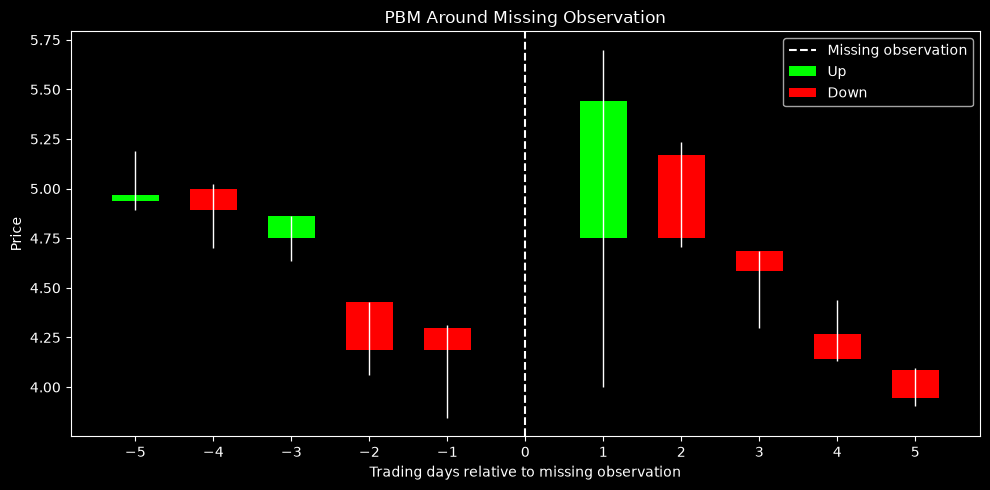

In [15]:
# Plot PBM around the missing trading date
missingDate = pd.Timestamp("2026-01-20")

pbmData = (
    marketData.loc[
        marketData["symbol"] == "PBM",
        ["date", "open", "high", "low", "close"]
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

beforeMissing = pbmData.loc[pbmData["date"] < missingDate].tail(5).copy()
afterMissing = pbmData.loc[pbmData["date"] > missingDate].head(5).copy()

beforeMissing["dayOffset"] = range(-5, 0)
afterMissing["dayOffset"] = range(1, 6)

pbmWindow = pd.concat([beforeMissing, afterMissing]).reset_index(drop=True)

upMask = pbmWindow["close"] >= pbmWindow["open"]
downMask = ~upMask

plt.figure(figsize=(10, 5))

plt.vlines(
    pbmWindow["dayOffset"],
    pbmWindow["low"],
    pbmWindow["high"],
    linewidth=1
)

plt.bar(
    pbmWindow.loc[upMask, "dayOffset"],
    pbmWindow.loc[upMask, "close"] - pbmWindow.loc[upMask, "open"],
    bottom=pbmWindow.loc[upMask, "open"],
    width=0.6,
    label="Up",
    color="lime"
)

plt.bar(
    pbmWindow.loc[downMask, "dayOffset"],
    pbmWindow.loc[downMask, "close"] - pbmWindow.loc[downMask, "open"],
    bottom=pbmWindow.loc[downMask, "open"],
    width=0.6,
    label="Down",
    color="red"
)

plt.axvline(0, linestyle="--", label="Missing observation")

plt.xticks(range(-5, 6))
plt.xlabel("Trading days relative to missing observation")
plt.ylabel("Price")
plt.title("PBM Around Missing Observation")
plt.legend()
plt.tight_layout()

plt.show()

In [16]:
# Check Yahoo history around the missing PBM observation
pbmCheck = yf.download(
    "PBM",
    start="2026-01-16",
    end="2026-01-23",
    auto_adjust=False,
    repair=True,
    progress=False
)

display(pbmCheck)

Price,Adj Close,Close,High,Low,Open,Repaired?,Volume
Ticker,PBM,PBM,PBM,PBM,PBM,PBM,PBM
Date,,,,,,,
2026-01-16,4.18750,4.18750,4.3125,3.84375,4.30000,True,81088
2026-01-21,5.44375,5.44375,5.7000,4.00000,4.75000,False,395136
2026-01-22,4.75000,4.75000,5.2375,4.70625,5.16875,False,66336


In [17]:
# Identify suspicious actively traded flat-price histories
staleData = marketData[["date", "symbol", "close", "volume"]].sort_values(["symbol", "date"]).reset_index(drop=True)

newRun = (
    staleData["symbol"].ne(staleData["symbol"].shift()) |
    staleData["close"].ne(staleData["close"].shift())
)

staleData["priceRun"] = newRun.groupby(staleData["symbol"]).cumsum()
staleData["traded"] = staleData["volume"] > 0

staleRuns = (
    staleData
    .groupby(["symbol", "priceRun"])
    .agg(
        firstDate=("date", "min"),
        lastDate=("date", "max"),
        close=("close", "first"),
        observations=("date", "size"),
        tradedDays=("traded", "sum")
    )
    .reset_index()
)

staleRuns["tradedRate"] = staleRuns["tradedDays"] / staleRuns["observations"]

suspiciousRuns = staleRuns.loc[
    (staleRuns["observations"] >= 20) &
    (staleRuns["tradedRate"] >= 0.80)
].copy()

suspiciousSymbols = sorted(suspiciousRuns["symbol"].unique())

print(f"Suspicious runs: {len(suspiciousRuns):,}")
print(f"Suspicious symbols: {len(suspiciousSymbols):,}")

display(
    suspiciousRuns
    .sort_values(["observations", "tradedRate"], ascending=False)
    .reset_index(drop=True)
)

Suspicious runs: 33
Suspicious symbols: 13


,symbol,priceRun,firstDate,lastDate,close,observations,tradedDays,tradedRate
0,MRDN,7,2018-06-07,2019-02-04,1.800000,166,165,0.993976
1,ATLX,117,2020-07-13,2020-12-18,0.750000,113,107,0.946903
2,MRDN,1,2018-01-02,2018-05-16,1.800000,94,92,0.978723
3,ATLX,58,2019-03-05,2019-07-03,0.750000,85,85,1.000000
4,SOWG,81,2019-10-11,2020-01-28,90.000000,74,65,0.878378
5,ATLX,30,2018-06-07,2018-08-02,1.500000,40,36,0.900000
6,GORO,224,2020-11-06,2020-12-30,1.200000,37,32,0.864865
7,ATLX,115,2020-05-19,2020-07-08,0.750000,35,35,1.000000
8,BESS,465,2023-05-05,2023-06-26,4.200000,35,28,0.800000
9,AEC,547,2023-06-16,2023-08-04,3.000000,34,34,1.000000


In [18]:
# Remove symbols with suspicious actively traded flat-price histories
rowsBeforeRemoval = len(marketData)
symbolsBeforeRemoval = marketData["symbol"].nunique()

marketData = marketData.loc[
    ~marketData["symbol"].isin(suspiciousSymbols)
].copy().reset_index(drop=True)

print(f"Suspicious symbols removed: {symbolsBeforeRemoval - marketData['symbol'].nunique():,}")
print(f"Rows removed: {rowsBeforeRemoval - len(marketData):,}")
print(f"Remaining symbols: {marketData['symbol'].nunique():,}")
print(f"Remaining rows: {len(marketData):,}")

Suspicious symbols removed: 13
Rows removed: 26,668
Remaining symbols: 5,221
Remaining rows: 8,808,211


Thirteen symbols containing prolonged periods of identical closing prices despite sustained trading activity were excluded as a conservative data-quality measure. These patterns could not be independently validated and were considered unreliable for modelling.

## Final Validation

In [19]:
# Validate cleaned market dataset
expectedColumns = ["date", "symbol", "open", "high", "low", "close", "adjClose", "volume"]

duplicateCount = marketData.duplicated(subset=["date", "symbol"]).sum()
missingCount = marketData[expectedColumns].isna().sum().sum()
nonfiniteCount = (~np.isfinite(marketData[["open", "high", "low", "close", "adjClose", "volume"]])).sum().sum()

nonpositivePriceCount = (marketData[["open", "high", "low", "close", "adjClose"]] <= 0).any(axis=1).sum()
negativeVolumeCount = (marketData["volume"] < 0).sum()

invalidHighCount = (
    (marketData["high"] < marketData["open"]) |
    (marketData["high"] < marketData["low"]) |
    (marketData["high"] < marketData["close"])
).sum()

invalidLowCount = (
    (marketData["low"] > marketData["open"]) |
    (marketData["low"] > marketData["high"]) |
    (marketData["low"] > marketData["close"])
).sum()

print(f"Rows: {len(marketData):,}")
print(f"Symbols: {marketData['symbol'].nunique():,}")
print(f"First date: {marketData['date'].min().date()}")
print(f"Last date: {marketData['date'].max().date()}")
print(f"Duplicate date-symbol rows: {duplicateCount:,}")
print(f"Missing values: {missingCount:,}")
print(f"Nonfinite values: {nonfiniteCount:,}")
print(f"Nonpositive price rows: {nonpositivePriceCount:,}")
print(f"Negative volume rows: {negativeVolumeCount:,}")
print(f"Invalid high rows: {invalidHighCount:,}")
print(f"Invalid low rows: {invalidLowCount:,}")

Rows: 8,808,211
Symbols: 5,221
First date: 2018-01-02
Last date: 2026-06-30
Duplicate date-symbol rows: 0
Missing values: 0
Nonfinite values: 0
Nonpositive price rows: 0
Negative volume rows: 0
Invalid high rows: 0
Invalid low rows: 0


## Save Clean Market Data

In [20]:
# Save cleaned market data
marketData = marketData.sort_values(["symbol", "date"]).reset_index(drop=True)

marketData.to_parquet(outputPath, index=False)

print(f"Saved: {outputPath}")
print(f"Rows: {len(marketData):,}")
print(f"Symbols: {marketData['symbol'].nunique():,}")

Saved: /Users/suhas/Documents/github/Quant-Research-Lab/data/pairDivergence/pairDivergenceData.parquet
Rows: 8,808,211
Symbols: 5,221
